# Task 1: Exploratory Data Analysis on Superstore Retail Sales
Analysis of purchase volume, monthly seasonality, category-wise revenue and discount sensitivity.

**Steps:** 1) Load & inspect, 2) Clean (nulls, dates, Year-Month), 3) Aggregate by Category / Region / Segment, 4) Monthly sales velocity, 5) Discount vs Profit, 6) Business findings.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
pd.options.display.float_format = '{:,.2f}'.format
PATH = 'superstore_sales.csv'   # change if the file lives elsewhere

## 1. Load and inspect

In [2]:
raw = pd.read_csv(PATH, encoding='latin1')
print('Raw shape:', raw.shape)
raw.info()

Raw shape: (10800, 21)
<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64

### Missing-value profiling
Only ~9,994 rows are real orders. The remaining rows are mostly empty, which suggests extra tables were appended to the file. Let's look.

In [3]:
print(raw.isna().sum()[lambda s: s > 0])
print('\nRows with no Order Date:', raw['Order Date'].isna().sum())
raw[raw['Order Date'].isna()].head(10).iloc[:, :3]

Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Rows with no Order Date: 806


,Row ID,Order ID,Order Date
9994,Person,Region,NaN
9995,Anna Andreadi,West,NaN
9996,Chuck Magee,East,NaN
9997,Kelly Williams,Central,NaN
9998,Cassandra Brandow,South,NaN
9999,Returned,Order ID,NaN
10000,Yes,CA-2015-100762,NaN
10001,Yes,CA-2015-100762,NaN
10002,Yes,CA-2015-100762,NaN
10003,Yes,CA-2015-100762,NaN


The 806 blank-date rows are **not orders**. They are the *People* (regional managers) and *Returns* sheets of the original Superstore workbook, concatenated into the CSV (e.g. `Row ID` holds names or `Yes`). They are removed, and the returned-order IDs are kept as a flag for later use.

In [4]:
# Keep returned-order IDs before dropping the stray rows
stray = raw[raw['Order Date'].isna()]
returned_ids = set(stray.loc[stray['Row ID'] == 'Yes', 'Order ID'])
print('Returned orders found:', len(returned_ids))

df = raw.dropna(subset=['Order Date']).copy()
print('Clean-order rows:', len(df))

Returned orders found: 296
Clean-order rows: 9994


## 2. Cleaning: types, dates, nulls, duplicates

In [5]:
df['Row ID'] = df['Row ID'].astype(int)
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date']  = pd.to_datetime(df['Ship Date'],  format='%m/%d/%Y')

# Remaining null: Postal Code for Burlington, VT (known ZIP 05401)
print('Null postal codes by city:', df.loc[df['Postal Code'].isna(), ['City','State']].drop_duplicates().values.tolist())
df.loc[(df['City']=='Burlington') & (df['State']=='Vermont') & df['Postal Code'].isna(), 'Postal Code'] = 5401
df['Postal Code'] = df['Postal Code'].astype(int).astype(str).str.zfill(5)

# Feature engineering
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Year-Month'] = df['Order Date'].dt.to_period('M')
df['Ship Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Profit Margin'] = df['Profit'] / df['Sales']
df['Returned'] = df['Order ID'].isin(returned_ids)

print('Duplicate rows:', df.duplicated().sum(), '| Duplicate Row IDs:', df['Row ID'].duplicated().sum())
print('Remaining nulls:', int(df.isna().sum().sum()))
print('Date range:', df['Order Date'].min().date(), 'to', df['Order Date'].max().date())
df.describe().T

Null postal codes by city: [['Burlington', 'Vermont']]
Duplicate rows: 0 | Duplicate Row IDs: 0
Remaining nulls: 0
Date range: 2015-01-03 to 2018-12-30


,count,mean,min,25%,50%,75%,max,std
Row ID,"9,994.00","4,997.50",1.00,"2,499.25","4,997.50","7,495.75","9,994.00","2,885.16"
Order Date,9994,2017-04-30 05:17:08.056834,2015-01-03 00:00:00,2016-05-23 00:00:00,2017-06-26 00:00:00,2018-05-14 00:00:00,2018-12-30 00:00:00,NaN
Ship Date,9994,2017-05-04 04:17:20.304182,2015-01-07 00:00:00,2016-05-27 00:00:00,2017-06-29 00:00:00,2018-05-18 00:00:00,2019-01-05 00:00:00,NaN
Sales,"9,994.00",229.86,0.44,17.28,54.49,209.94,"22,638.48",623.25
Quantity,"9,994.00",3.79,1.00,2.00,3.00,5.00,14.00,2.23
Discount,"9,994.00",0.16,0.00,0.00,0.20,0.20,0.80,0.21
Profit,"9,994.00",28.66,"-6,599.98",1.73,8.67,29.36,"8,399.98",234.26
Year,"9,994.00","2,016.72","2,015.00","2,016.00","2,017.00","2,018.00","2,018.00",1.12
Month,"9,994.00",7.81,1.00,5.00,9.00,11.00,12.00,3.28
Ship Days,"9,994.00",3.96,0.00,3.00,4.00,5.00,7.00,1.75


## 3. Aggregate Sales & Profit

In [6]:
def agg(col):
    g = df.groupby(col).agg(Orders=('Order ID','nunique'), Sales=('Sales','sum'), Profit=('Profit','sum'))
    g['Margin %'] = g['Profit'] / g['Sales'] * 100
    return g.sort_values('Sales', ascending=False)

print('TOTAL  Sales: {:,.0f} | Profit: {:,.0f} | Margin: {:.1f}%'.format(df.Sales.sum(), df.Profit.sum(), df.Profit.sum()/df.Sales.sum()*100))
for c in ['Category','Region','Segment']:
    display(agg(c))

TOTAL  Sales: 2,297,201 | Profit: 286,397 | Margin: 12.5%


,Orders,Sales,Profit,Margin %
Category,,,,
Technology,1544,"836,154.03","145,454.95",17.40
Furniture,1764,"741,999.80","18,451.27",2.49
Office Supplies,3742,"719,047.03","122,490.80",17.04


,Orders,Sales,Profit,Margin %
Region,,,,
West,1611,"725,457.82","108,418.45",14.94
East,1401,"678,781.24","91,522.78",13.48
Central,1175,"501,239.89","39,706.36",7.92
South,822,"391,721.91","46,749.43",11.93


,Orders,Sales,Profit,Margin %
Segment,,,,
Consumer,2586,"1,161,401.34","134,119.21",11.55
Corporate,1514,"706,146.37","91,979.13",13.03
Home Office,909,"429,653.15","60,298.68",14.03


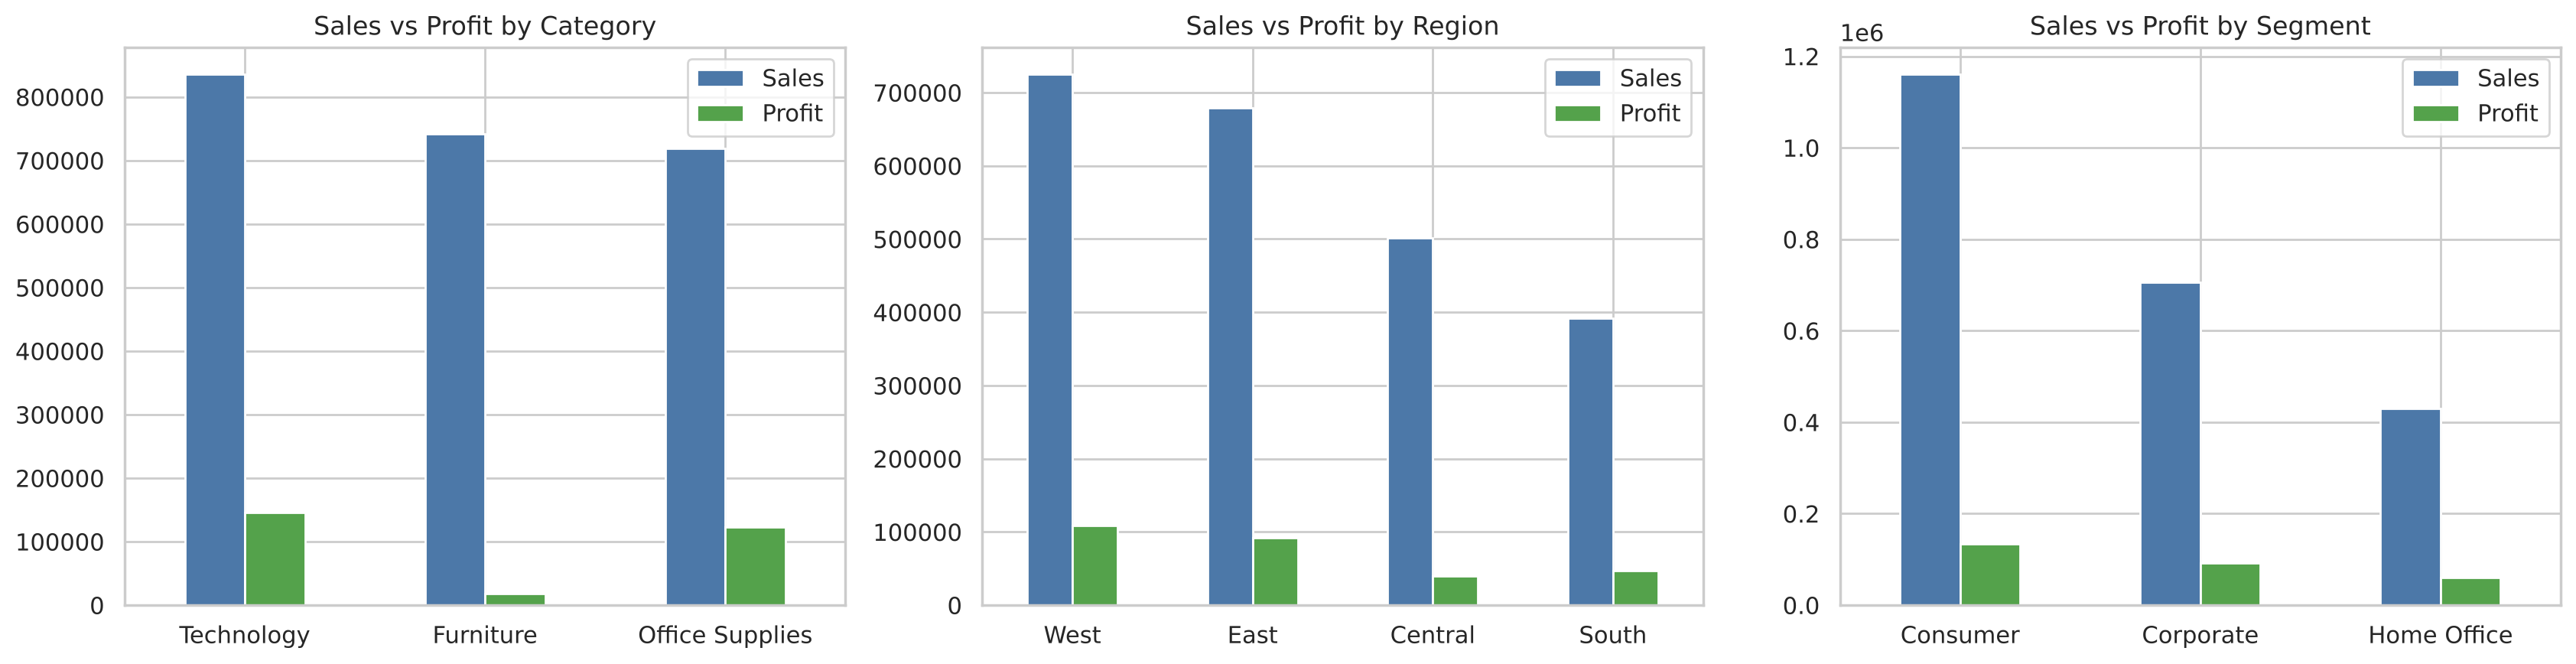

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ['Category','Region','Segment']):
    g = agg(c)[['Sales','Profit']]
    g.plot(kind='bar', ax=ax, color=['#4C78A8','#54A24B'])
    ax.set_title(f'Sales vs Profit by {c}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

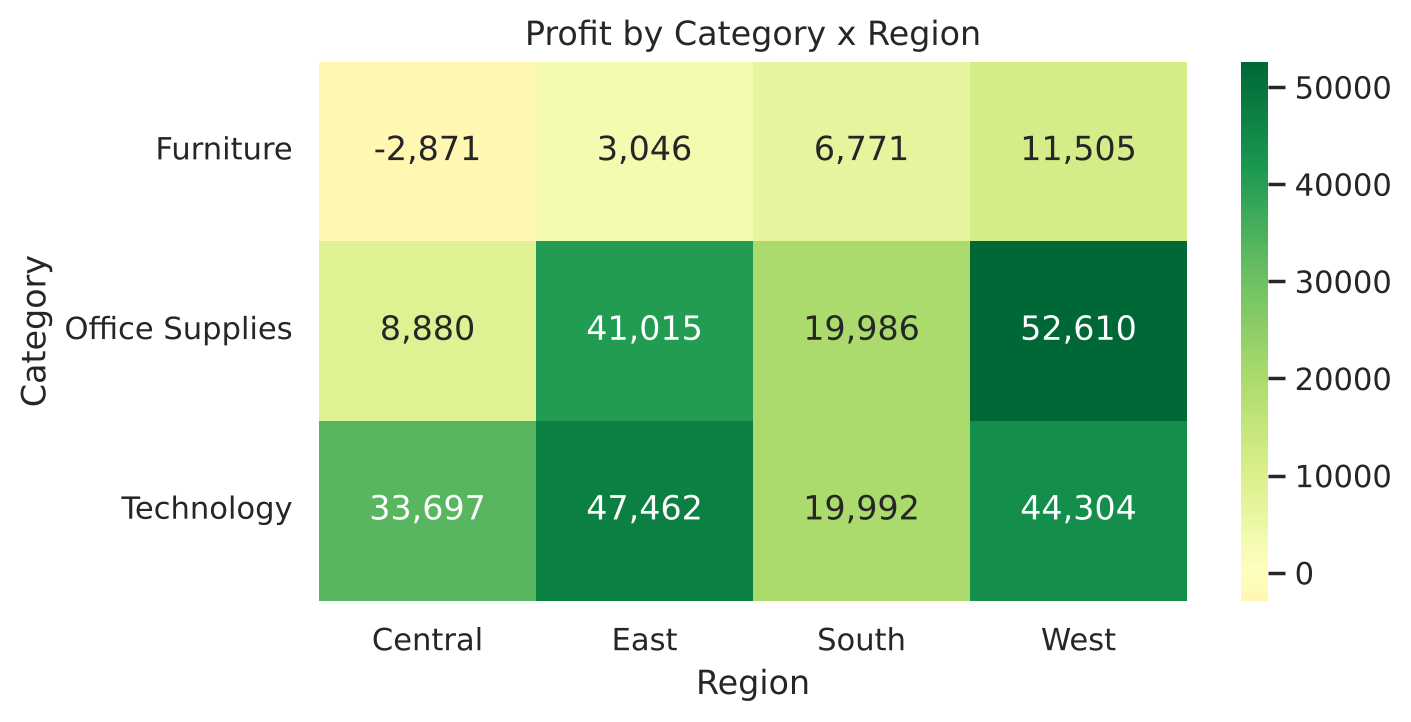

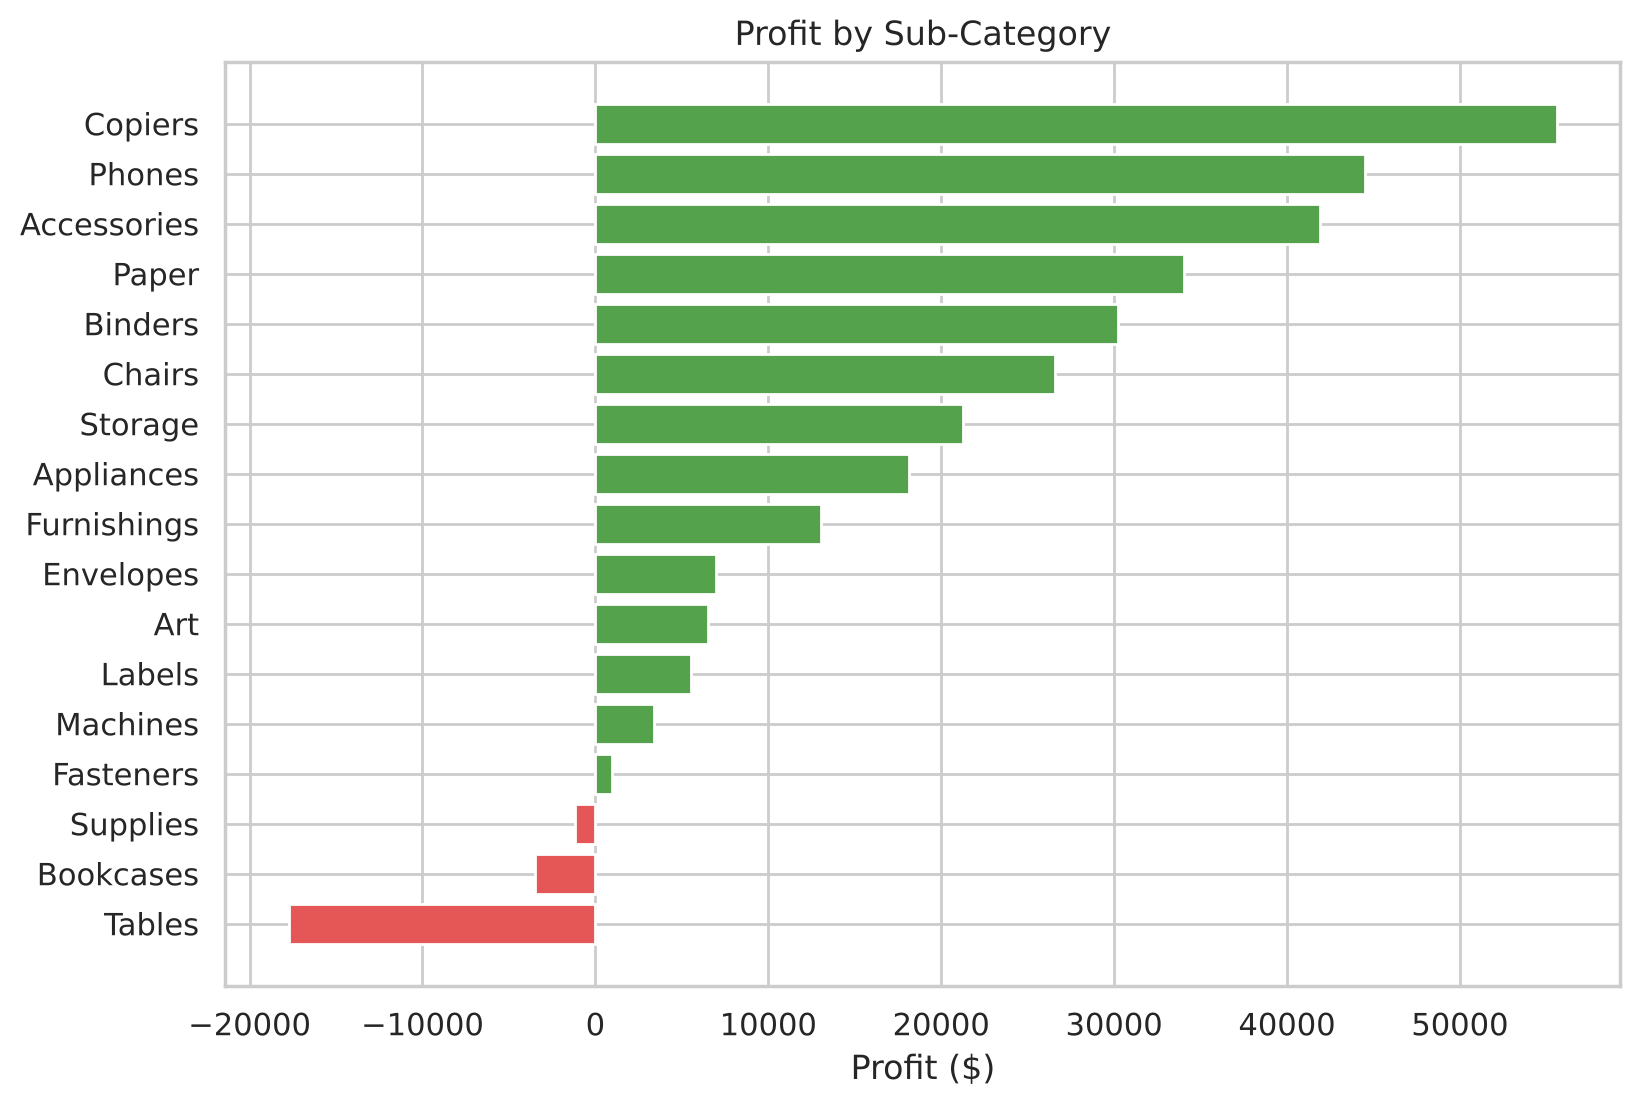

In [8]:
pivot = df.pivot_table(index='Category', columns='Region', values='Profit', aggfunc='sum')
plt.figure(figsize=(7,3.5)); sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='RdYlGn', center=0)
plt.title('Profit by Category x Region'); plt.show()

sub = df.groupby('Sub-Category')[['Sales','Profit']].sum().sort_values('Profit')
plt.figure(figsize=(9,6))
plt.barh(sub.index, sub['Profit'], color=np.where(sub['Profit']<0,'#E45756','#54A24B'))
plt.title('Profit by Sub-Category'); plt.xlabel('Profit ($)'); plt.show()

## 4. Monthly sales velocity and seasonality

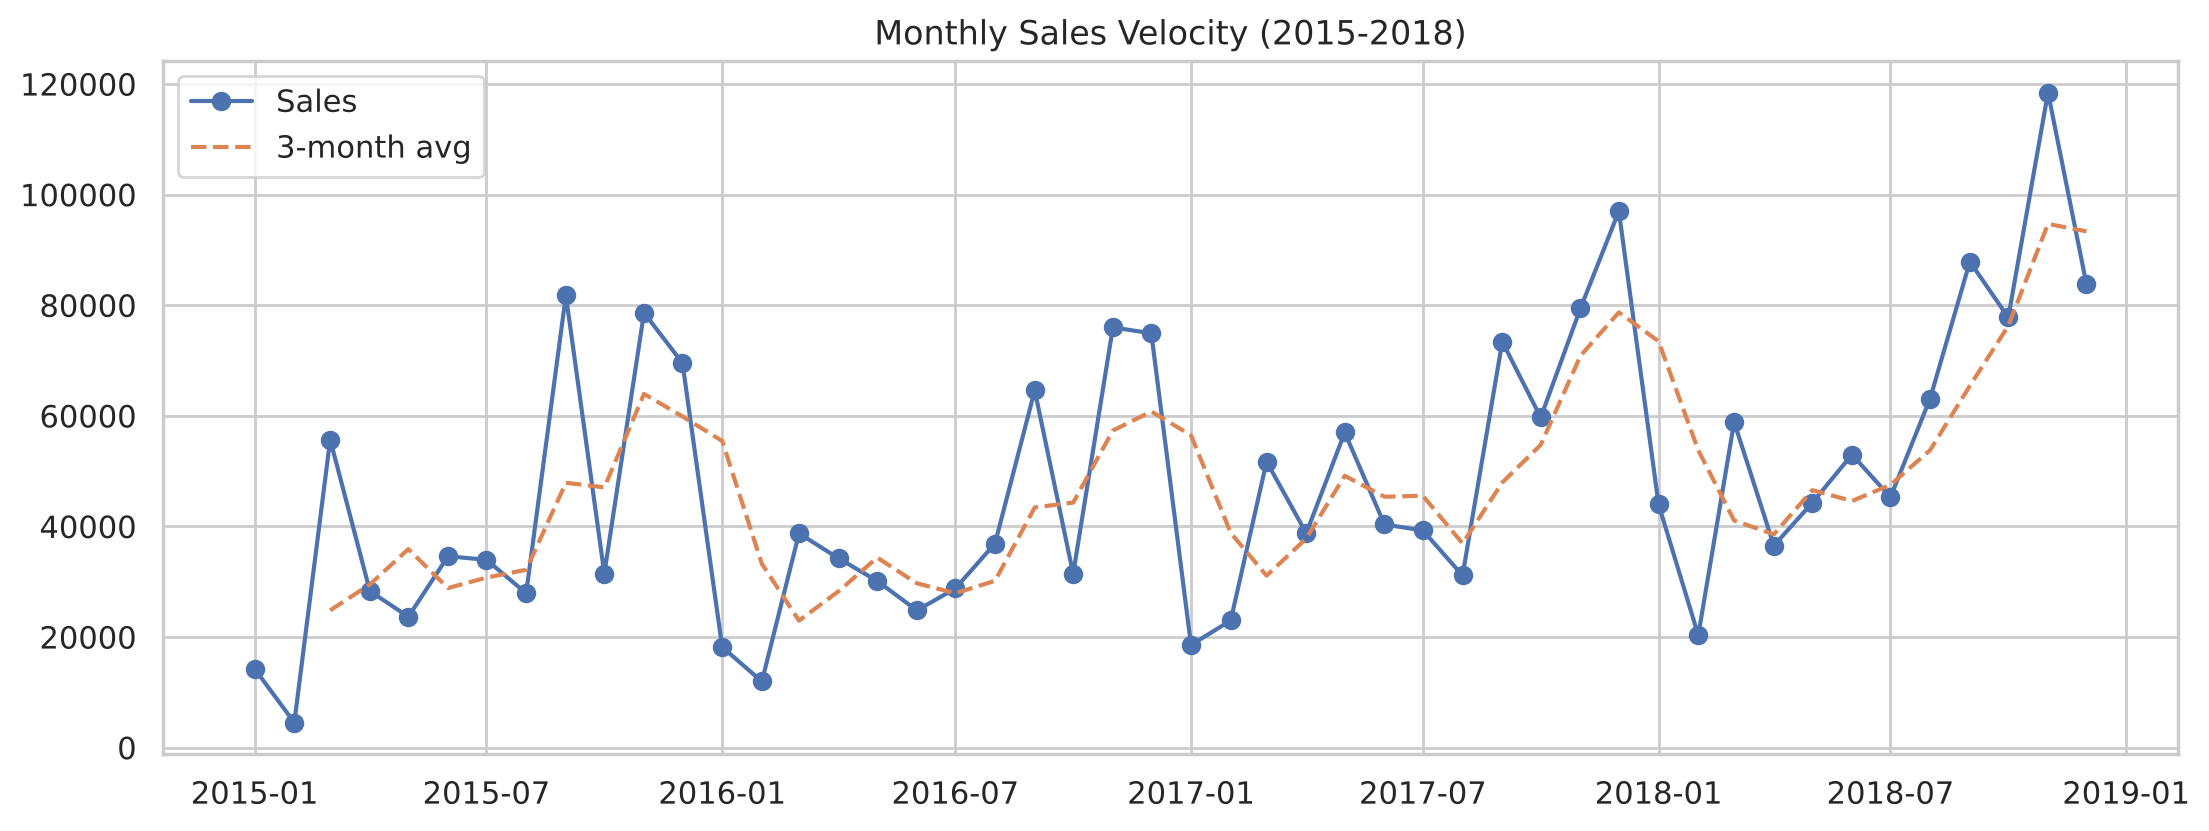

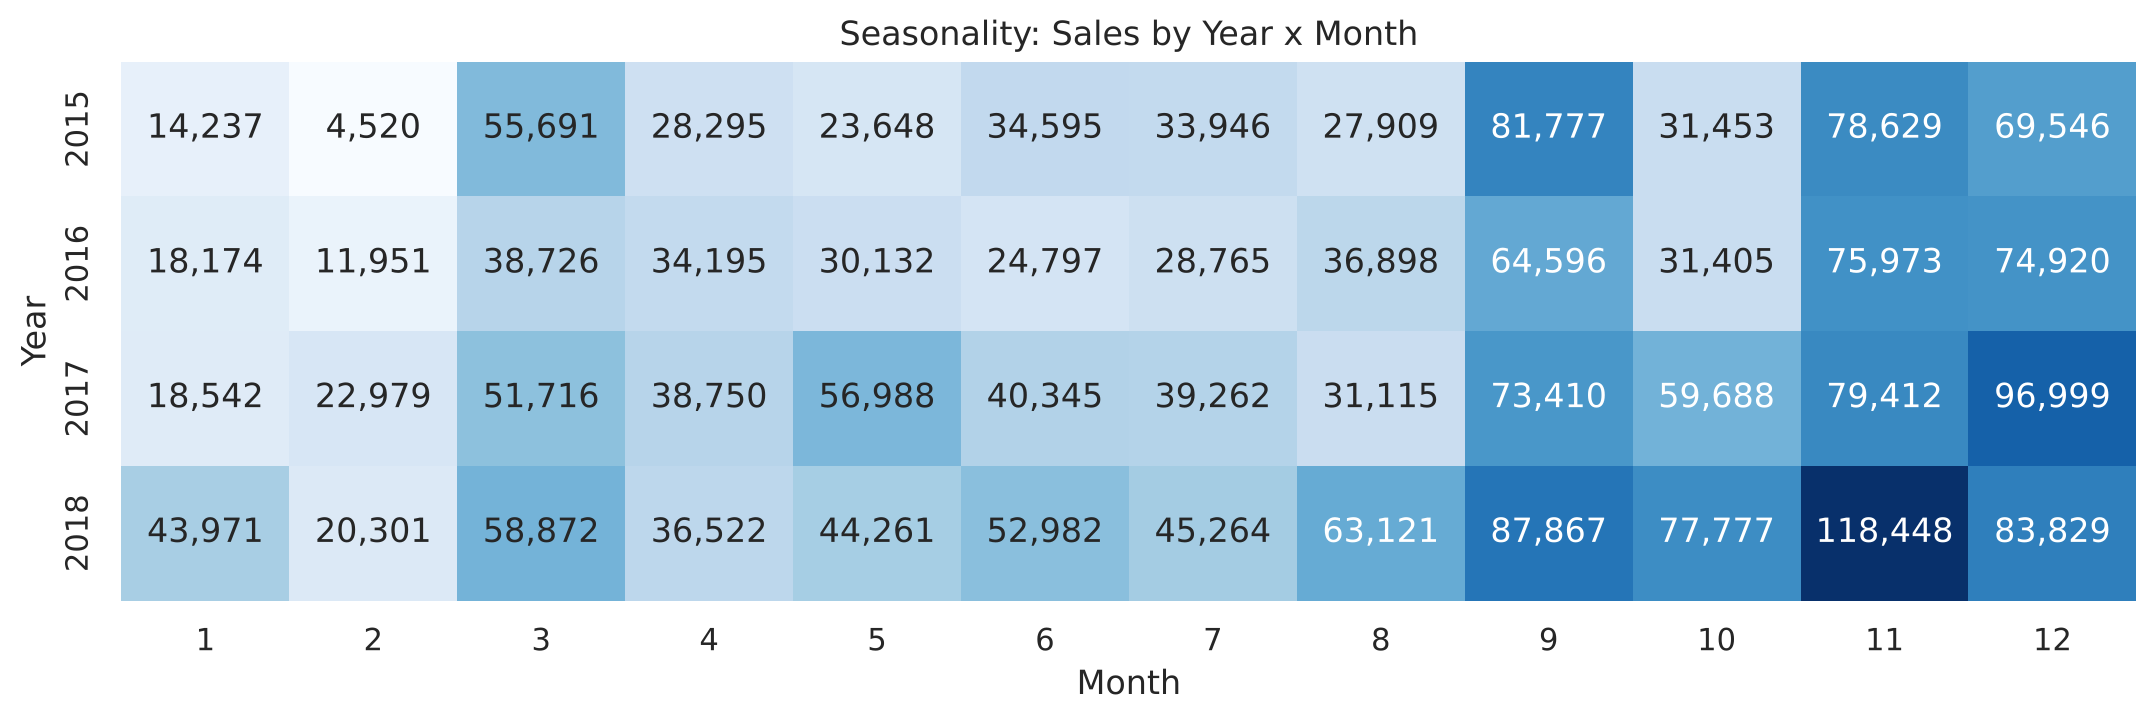

Share of annual sales in Mar, Sep, Nov, Dec: 51.8%


,Sales,Profit,Sales YoY %
Year,,,
2015,"484,247.50","49,543.97",NaN
2016,"470,532.51","61,618.60",-2.83
2017,"609,205.60","81,795.17",29.47
2018,"733,215.26","93,439.27",20.36


In [9]:
monthly = df.groupby('Year-Month')[['Sales','Profit']].sum()
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(monthly.index, monthly['Sales'], marker='o', label='Sales')
ax.plot(monthly.index, monthly['Sales'].rolling(3).mean(), ls='--', label='3-month avg')
ax.set_title('Monthly Sales Velocity (2015-2018)'); ax.legend(); plt.show()

season = df.pivot_table(index='Year', columns='Month', values='Sales', aggfunc='sum')
plt.figure(figsize=(13,3.5)); sns.heatmap(season, annot=True, fmt=',.0f', cmap='Blues', cbar=False)
plt.title('Seasonality: Sales by Year x Month'); plt.show()

avg_month = df.groupby('Month')['Sales'].sum() / df['Year'].nunique()
print('Share of annual sales in Mar, Sep, Nov, Dec: {:.1%}'.format(df[df.Month.isin([3,9,11,12])].Sales.sum()/df.Sales.sum()))
yearly = df.groupby('Year')[['Sales','Profit']].sum(); yearly['Sales YoY %'] = yearly['Sales'].pct_change()*100
yearly

## 5. Discount sensitivity

/tmp/ipykernel_125/282260421.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=band.index, y=band['Margin %'], ax=ax[1], palette='RdYlGn')


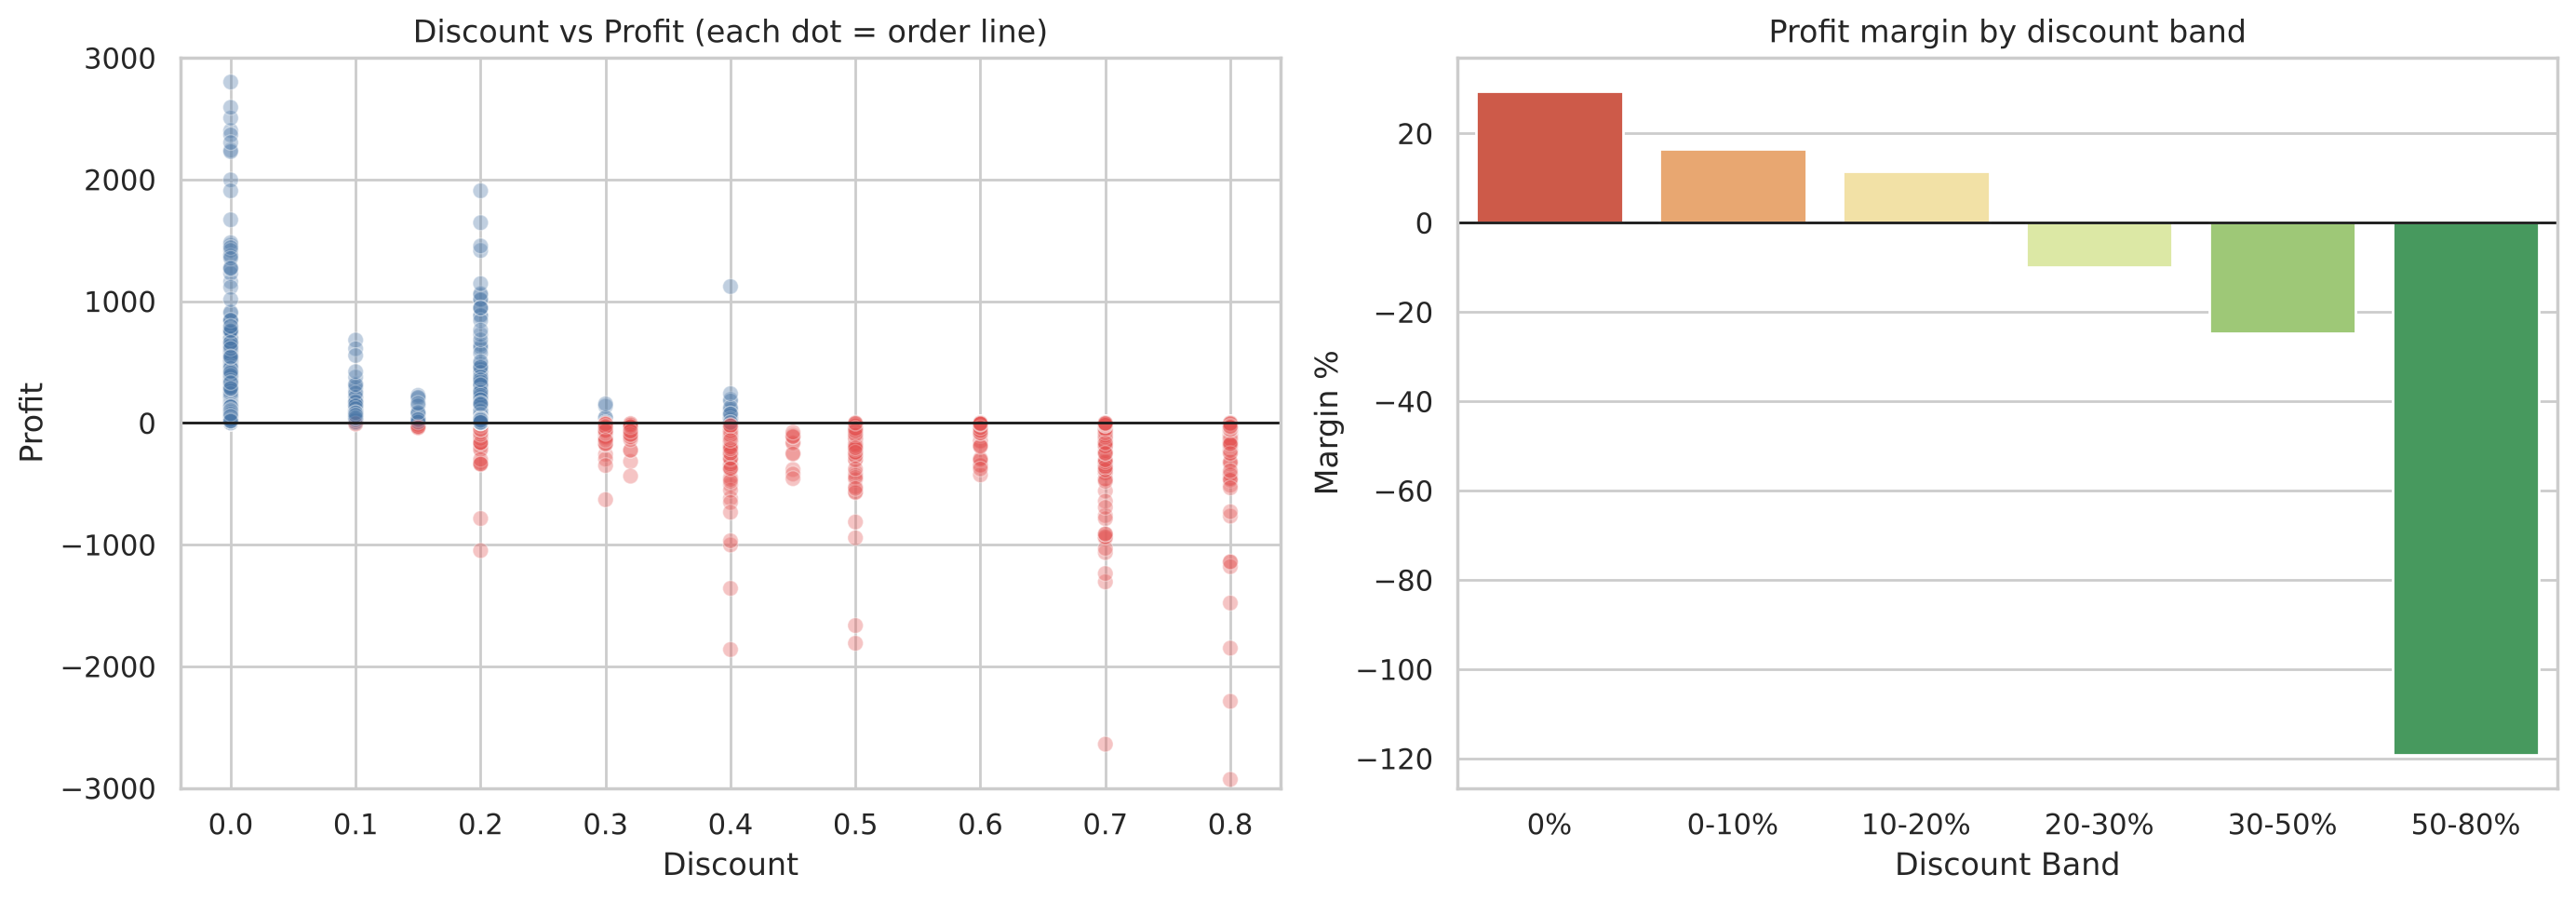

Correlation (Discount, Profit): -0.219


,Lines,Sales,Profit,LossShare,Margin %
Discount Band,,,,,
0%,4798,"1,087,908.47","320,987.60",0.00,29.51
0-10%,94,"54,369.35","9,029.18",0.04,16.61
10-20%,3709,"792,152.89","91,756.30",0.14,11.58
20-30%,227,"103,226.65","-10,369.28",0.92,-10.05
30-50%,310,"195,314.76","-48,447.73",0.92,-24.80
50-80%,856,"64,228.74","-76,559.05",1.00,-119.20


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=.35, hue=(df['Profit']<0), palette={True:'#E45756', False:'#4C78A8'}, legend=False, ax=ax[0])
ax[0].axhline(0, color='k', lw=1); ax[0].set_title('Discount vs Profit (each dot = order line)')
ax[0].set_ylim(-3000, 3000)

df['Discount Band'] = pd.cut(df['Discount'], [-.01,0,.1,.2,.3,.5,.8], labels=['0%','0-10%','10-20%','20-30%','30-50%','50-80%'])
band = df.groupby('Discount Band', observed=True).agg(Lines=('Sales','size'), Sales=('Sales','sum'), Profit=('Profit','sum'), LossShare=('Profit', lambda x:(x<0).mean()))
band['Margin %'] = band['Profit']/band['Sales']*100
sns.barplot(x=band.index, y=band['Margin %'], ax=ax[1], palette='RdYlGn')
ax[1].axhline(0, color='k', lw=1); ax[1].set_title('Profit margin by discount band'); plt.tight_layout(); plt.show()
print('Correlation (Discount, Profit): {:.3f}'.format(df[['Discount','Profit']].corr().iloc[0,1]))
band

In [11]:
# Where does discounting hurt? Category x discount>20%
heavy = df[df['Discount']>0.2].groupby('Category')[['Sales','Profit']].sum()
print('Profit on lines discounted >20%:'); display(heavy)
print('Total profit lost on >20% discount lines: {:,.0f}'.format(df.loc[df.Discount>0.2,'Profit'].sum()))
df.groupby('State')['Profit'].sum().sort_values().head(5)

Profit on lines discounted >20%:


,Sales,Profit
Category,,
Furniture,"195,150.74","-54,477.76"
Office Supplies,"39,523.15","-47,140.14"
Technology,"128,096.26","-33,758.16"


Total profit lost on >20% discount lines: -135,376


State
Texas            -25,729.36
Ohio             -16,971.38
Pennsylvania     -15,559.96
Illinois         -12,607.89
North Carolina    -7,490.91
Name: Profit, dtype: float64

In [12]:
# Customer concentration + returns (bonus)
cust = df.groupby('Customer ID')['Sales'].sum().sort_values(ascending=False)
print('Top 20% of customers drive {:.1%} of sales ({} customers total)'.format(cust.head(int(len(cust)*.2)).sum()/cust.sum(), len(cust)))
print('Share of orders returned: {:.1%}'.format(df.drop_duplicates('Order ID')['Returned'].mean()))

Top 20% of customers drive 48.0% of sales (793 customers total)
Share of orders returned: 5.9%


## 6. Executive takeaways

1. **Healthy, growing business, but margin is only ~12.5%.** Sales of ~\$2.30M and profit of ~\$286K over 2015-2018. Sales dipped slightly in 2016 (-2.8%), then grew 29% in 2017 and 20% in 2018 to \$733K. Profit grew in every year (\$49.5K to \$93.4K).
2. **Sales are strongly seasonal with a Q4 peak and a September spike.** November (~\$352K) and December (~\$325K) plus September (~\$308K) and March (~\$205K) are the biggest months. January-February are the weakest (Feb ~\$60K, under 1/5 of November). *Action:* build inventory and campaigns ahead of Sep and Nov-Dec, and use Q1 for clearance or B2B pushes.
3. **Furniture is a revenue-rich but profit-poor category.** It brings in ~\$742K (32% of sales) but only ~\$18K profit (2.5% margin) vs ~17% for Technology and Office Supplies. Technology is the top earner (\$836K sales, \$145K profit).
4. **Discounts above ~20% destroy profit.** Orders with no discount earn a ~29.5% margin and 10-20% discounts ~11.6%, but 20-30% (-10%), 30-50% (-25%) and 50-80% (-119%) are loss-making, with >90% of such lines unprofitable. Discount and profit are negatively correlated (r = -0.22). Lines discounted above 20% lose ~\$135K combined. *Action:* cap discounts at ~20% and require approval beyond that.
5. **Loss-makers are concentrated.** Tables (-\$17.7K), Bookcases (-\$3.5K) and Supplies (-\$1.2K) lose money in total, and Tables/Bookcases drive Furniture's weak margin. Central region has the lowest margin (7.9% vs 14.9% for West), Furniture in Central loses money, and Texas, Ohio, Pennsylvania and Illinois are the biggest loss-making states, which are heavy-discount markets.
6. **Segment & customers:** Consumer is 51% of sales, but Corporate (13.0%) and Home Office (14.0%) earn better margins. The top 20% of customers generate ~48% of revenue, so retention programs for them matter.
7. **Data quality note:** the CSV had 806 non-order rows (People and Returns sheets appended). They were removed, with returned order IDs kept as a flag, and the 11 missing postal codes (Burlington, VT) were imputed.